In [ ]:
import random, os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'  # 必须放在导入其他库之前
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from matplotlib import pyplot as plt
from datetime import *
from real2D_Env import Env
# from real2D_env222 import Env


In [ ]:
import gymnasium as gym

from stable_baselines3 import PPO

env = gym.make("CartPole-v1", render_mode="human")

model = PPO("MlpPolicy", env, verbose=1)
model.learn(total_timesteps=10_000)

vec_env = model.get_env()
obs = vec_env.reset()
for i in range(1000):
    action, _states = model.predict(obs, deterministic=True)
    obs, reward, done, info = vec_env.step(action)
    vec_env.render()
    # VecEnv resets automatically
    # if done:
    #   obs = env.reset()

env.close()

In [ ]:
env=Env()
env.reset()


In [ ]:
env.visualization()

In [1]:
import random, os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'  # 必须放在导入其他库之前
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from matplotlib import pyplot as plt
from datetime import *
from real2D_Env_Gym import SeaEnv
import gymnasium as gym

In [ ]:
gym.spaces.Box(low=np.array([0.0, 0.0, -10.0, -10.0, 0.0, 0.0]), high=np.array([40.0, 40.0, 10.0, 10.0, 40.0, 40.0]), dtype=np.float32)

In [5]:
# Register the environment so we can create it with gym.make()
gym.register(
    id="myenv/SeaEnv-v0",
    entry_point=SeaEnv,
)
# 2. 创建环境实例
env = gym.make("myenv/SeaEnv-v0")  # 使用注册的id创建环境
from gymnasium.utils.env_checker import check_env
# This will catch many common issues
try:
    check_env(env)
    print("Environment passes all checks!")
except Exception as e:
    print(f"Environment has issues: {e}")

Environment passes all checks!


c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\utils\env_checker.py:384: UserWarning: WARN: The environment (<OrderEnforcing<PassiveEnvChecker<SeaEnv<myenv/SeaEnv-v0>>>>) is different from the unwrapped version (<SeaEnv<myenv/SeaEnv-v0>>). This could effect the environment checker as the environment most likely has a wrapper applied to it. We recommend using the raw environment for `check_env` using `env.unwrapped`.
  logger.warn(
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\utils\passive_env_checker.py:134: UserWarning: WARN: The obs returned by the `step()` method was expecting numpy array dtype to be float32, actual type: float64
  logger.warn(
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\utils\passive_env_checker.py:158: UserWarning: WARN: The obs returned by the `step()` method is not within the observation space.
  logger.warn(f"{pre} is not within the observation space.")


In [6]:
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
# Parallel environments
vec_env = make_vec_env("myenv/SeaEnv-v0", n_envs=4)
model = PPO("MlpPolicy", vec_env, verbose=1)
model.learn(total_timesteps=25000)
model.save("ppo_SeaEnv")


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\envs\registration.py:736: UserWarning: WARN: The environment is being initialised with render_mode='rgb_array' that is not in the possible render_modes ([]).
  logger.warn(
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\spaces\box.py:235: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
c:\Users\Administrator\miniconda3\envs\Ha

Using cpu device


c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\utils\passive_env_checker.py:134: UserWarning: WARN: The obs returned by the `step()` method was expecting numpy array dtype to be float32, actual type: float64
  logger.warn(
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\utils\passive_env_checker.py:158: UserWarning: WARN: The obs returned by the `step()` method is not within the observation space.
  logger.warn(f"{pre} is not within the observation space.")


----------------------------------
| rollout/           |           |
|    ep_len_mean     | 1e+03     |
|    ep_rew_mean     | -8.22e+03 |
| time/              |           |
|    fps             | 190       |
|    iterations      | 1         |
|    time_elapsed    | 42        |
|    total_timesteps | 8192      |
----------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 1e+03       |
|    ep_rew_mean          | -6.6e+03    |
| time/                   |             |
|    fps                  | 183         |
|    iterations           | 2           |
|    time_elapsed         | 89          |
|    total_timesteps      | 16384       |
| train/                  |             |
|    approx_kl            | 0.012189691 |
|    clip_fraction        | 0.0669      |
|    clip_range           | 0.2         |
|    entropy_loss         | -2.07       |
|    explained_variance   | 0.000645    |
|    learning_rate  

c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\envs\registration.py:644: UserWarning: WARN: Overriding environment myenv/SeaEnv-v0 already in registry.
  logger.warn(f"Overriding environment {new_spec.id} already in registry.")
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\spaces\box.py:235: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\spaces\box.py:305: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


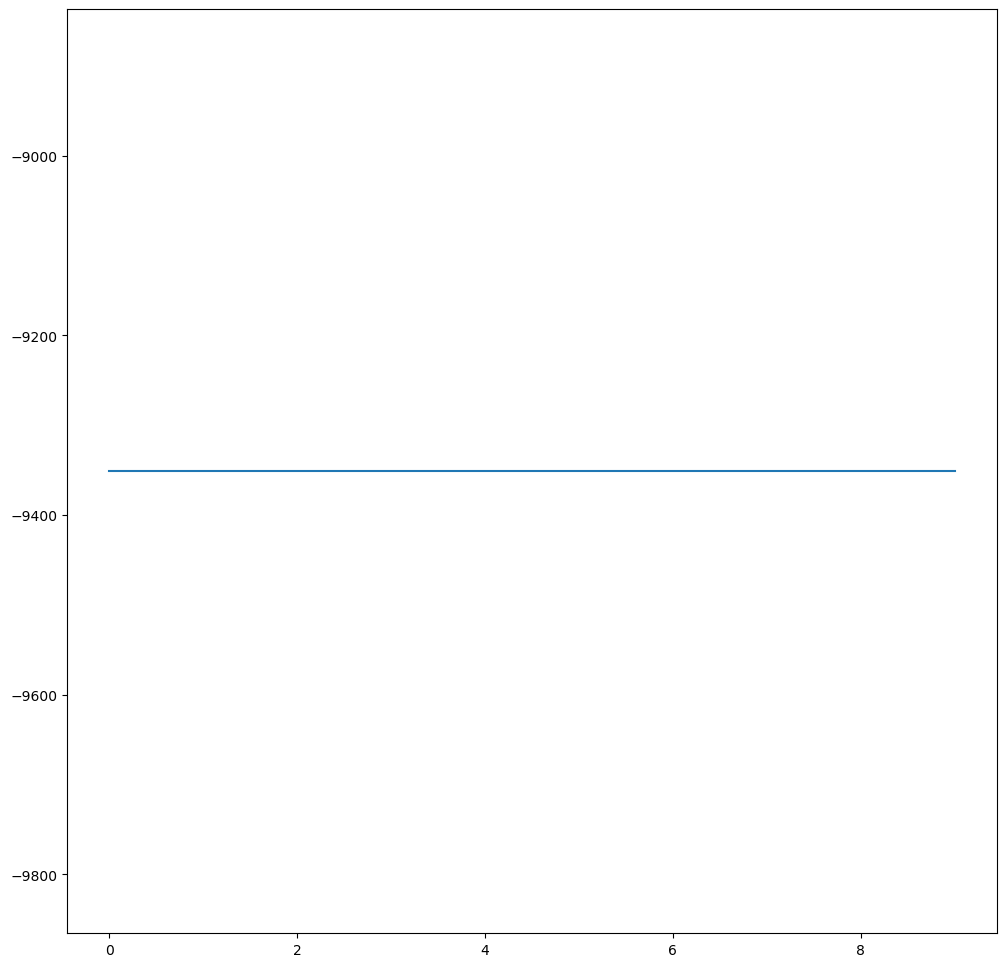

In [7]:

# 创建测试环境（使用与训练相同的环境参数）
# env = gym.make("myenv/SeaEnv-v0") 
# from stable_baselines3.common.env_util import make_vec_env
# Parallel environments
# vec_env = make_vec_env("myenv/SeaEnv-v0", n_envs=4)
# obs = vec_env.reset()
# while True:
#     action, _states = model.predict(obs)
#     obs, rewards, dones, info = vec_env.step(action)

from stable_baselines3 import PPO
import gymnasium as gym
import matplotlib.pyplot as plt

model = PPO.load("ppo_SeaEnv")

# Register the environment so we can create it with gym.make()
gym.register(
    id="myenv/SeaEnv-v0",
    entry_point=SeaEnv,
)
env = gym.make("myenv/SeaEnv-v0")

episode_rewards = []
for _ in range(10):
    # 显式解包观测值和info字典
    obs, info = env.reset()  # 新版Gym返回元组
    terminated = False
    truncated = False
    total_reward = 0
    
    while not (terminated or truncated):
        action, _ = model.predict(obs, deterministic=True)  # 确保传入的是numpy数组
        # 新版Gym返回5个值
        obs, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
    
    episode_rewards.append(total_reward)

plt.plot(episode_rewards)
plt.show()


c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\spaces\box.py:235: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\spaces\box.py:305: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


(<Figure size 1200x1200 with 1 Axes>,
 <Axes: title={'center': 'Multi-Goal AUV Navigation Environment'}, xlabel='X Coordinate', ylabel='Y Coordinate'>)

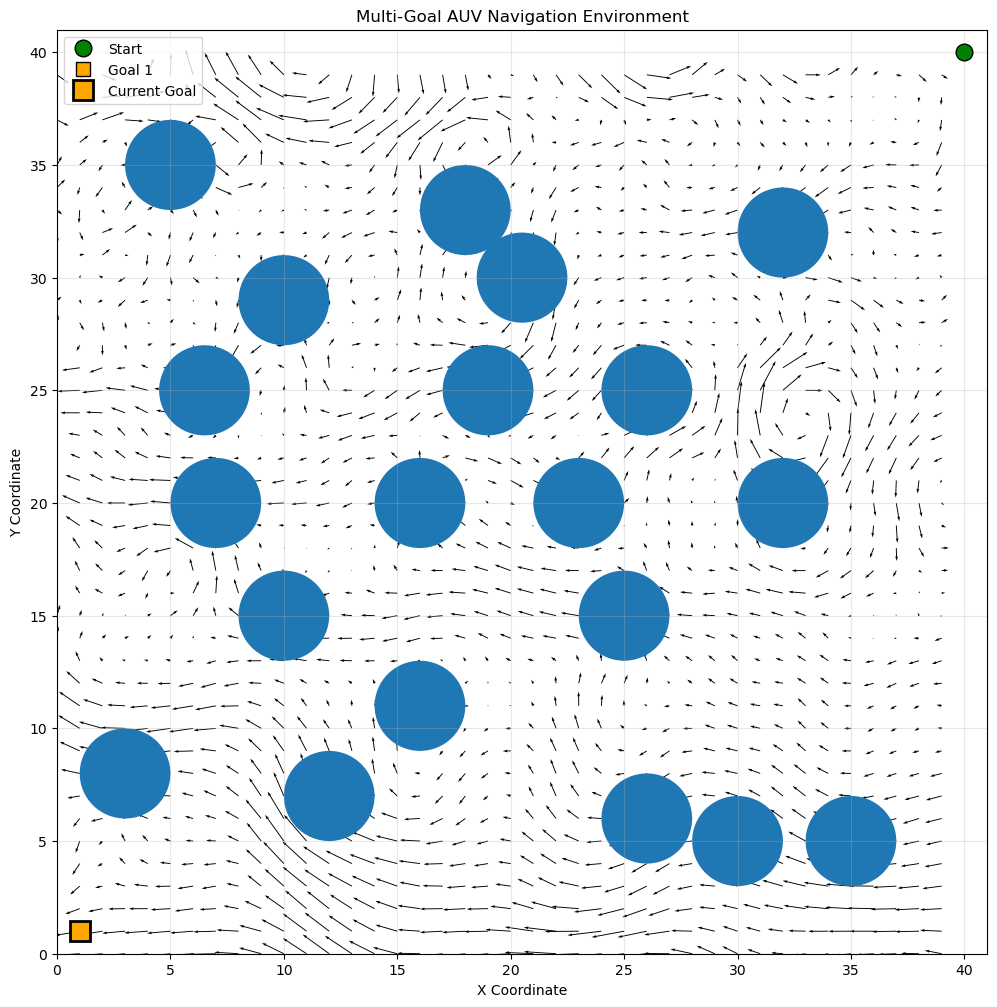

In [3]:
# del env
env=SeaEnv()
env.reset()
env.visualization()

<Axes: title={'center': 'Multi-Goal AUV Navigation Environment'}, xlabel='X Coordinate', ylabel='Y Coordinate'>

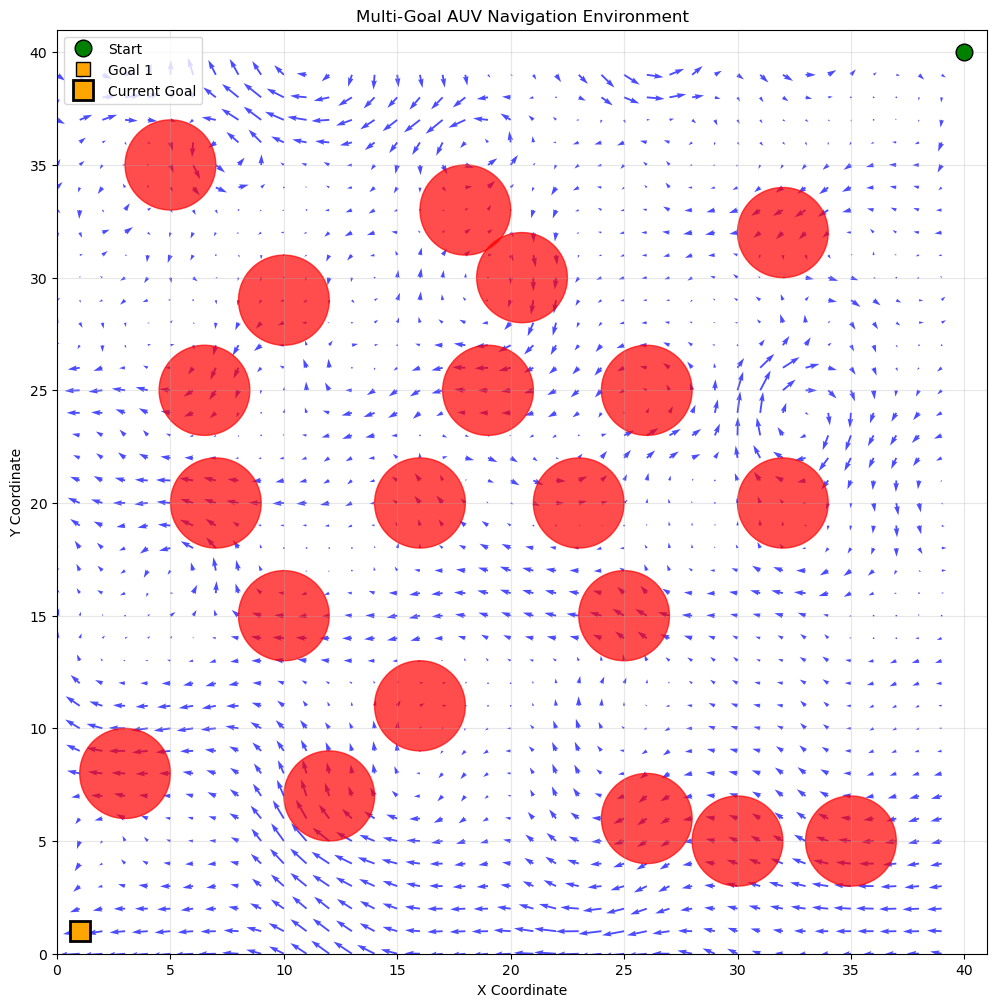

In [4]:
env.clearax()

Path coordinates (x): [40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0,

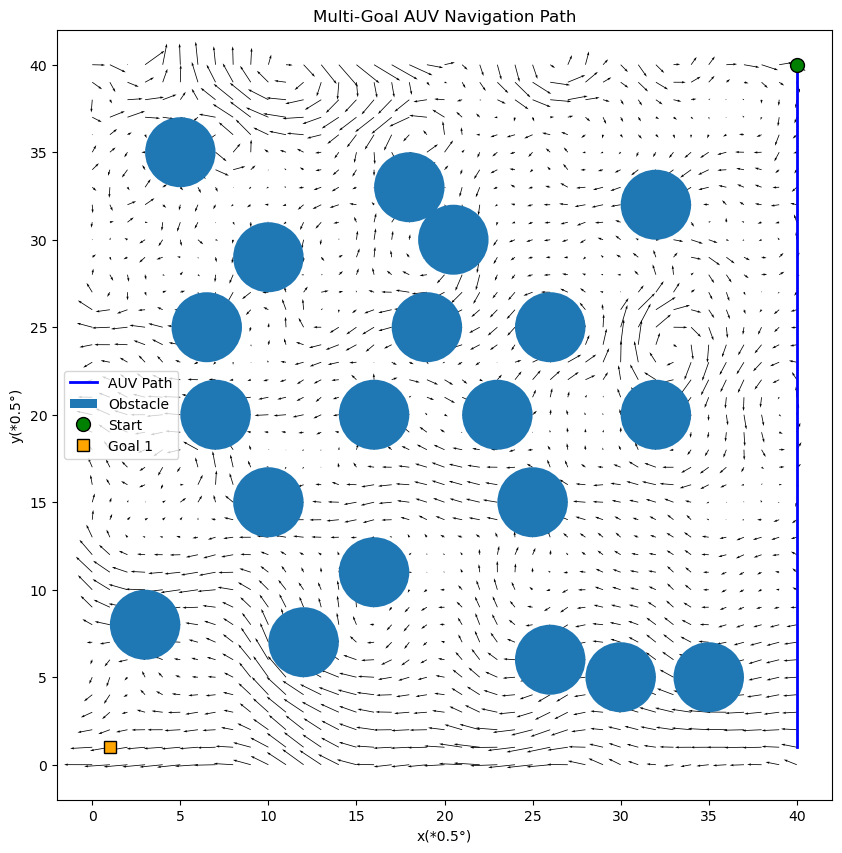

In [8]:
from stable_baselines3 import PPO
import gymnasium as gym
import matplotlib.pyplot as plt

model = PPO.load("ppo_SeaEnv")

# Register the environment so we can create it with gym.make()
# gym.register(
#     id="myenv/SeaEnv-v0",
#     entry_point=SeaEnv,
# )
# env = gym.make("myenv/SeaEnv-v0")
env = SeaEnv()
weight_reward = None
reward_total = 0
count=0
nstate_list = []

# 显式解包观测值和info字典
obs, info = env.reset()  # 新版Gym返回元组

terminated = False
truncated = False

while not (terminated or truncated):
    action, _ = model.predict(obs, deterministic=True)  # 确保传入的是numpy数组
    # 新版Gym返回5个值
    count += 1
    next_obs, reward, terminated, truncated, info = env.step(action)
    
    nstate_list.append(next_obs)

    reward_total += reward
    obs = next_obs

    if count > 500:
        break
    if terminated:
        nstate_list.append(next_obs)
        nstate_list.append('')
        if not weight_reward:  # 第一次进入循环时设置初始值
            weight_reward = reward_total
        else:
            weight_reward = 0.99 * weight_reward + 0.01 * reward_total
        print('episode: {}  epsilon: {:.2f}  reward: {}  weight_reward: {:.3f}'.format(i+1, reward_total, weight_reward))
        break
env.final(nstate_list)
